<div align="center">

# Assignment 9 — K-Means Clustering & Partitioning Algorithms

---

**Name:** Shreyas Sovani &nbsp;|&nbsp; **Roll No:** 22 &nbsp;|&nbsp; **Class:** AIML-F &nbsp;|&nbsp; **Subject:** Machine Learning

---

</div>


# Assignment 9 — K-Means Clustering & Partitioning Algorithms

*Unsupervised Learning: Lloyd's Algorithm, K-Means++, Elbow Method, and Silhouette Analysis*

**Datasets:** Synthetic Gaussian blobs (known ground truth) and Iris (150 flowers, 4 measurements) — built into scikit-learn.

**Objective:** Implement Lloyd's algorithm with random and K-Means++ initialisation from scratch, verify it against scikit-learn, and choose the number of clusters with the elbow method and silhouette analysis.

## 1. Theory

A **partitioning algorithm** splits $n$ points into $K$ non-overlapping clusters. K-Means picks the partition that minimises the **within-cluster sum of squares** (WCSS, also called *inertia*):

$$J = \sum_{k=1}^{K} \sum_{\mathbf{x}_i \in C_k} \lVert \mathbf{x}_i - \boldsymbol{\mu}_k \rVert^2$$

**Lloyd's algorithm** (the standard K-Means procedure):

1. **Initialise** $K$ centroids $\boldsymbol{\mu}_1, \dots, \boldsymbol{\mu}_K$
2. **Assignment step** — give each point to its nearest centroid: $c_i = \arg\min_k \lVert \mathbf{x}_i - \boldsymbol{\mu}_k \rVert^2$
3. **Update step** — move each centroid to the mean of its points: $\boldsymbol{\mu}_k = \frac{1}{\lvert C_k \rvert} \sum_{\mathbf{x}_i \in C_k} \mathbf{x}_i$
4. Repeat steps 2–3 until the assignments stop changing

Neither step can increase $J$, so the algorithm always converges — but only to a **local** minimum that depends on the starting centroids.

**K-Means++ initialisation** spreads the starting centroids out: the first is a random data point, and each next centroid is drawn with probability proportional to $D(\mathbf{x})^2$, the squared distance from $\mathbf{x}$ to the nearest centroid chosen so far.

**Choosing K:**

- **Elbow method** — plot $J$ against $K$ and pick the "elbow" where adding clusters stops paying off ($J$ always falls as $K$ grows, so the minimum is useless).
- **Silhouette analysis** — for point $i$, let $a(i)$ be its mean distance to points in its own cluster and $b(i)$ its mean distance to points in the nearest other cluster:

$$s(i) = \frac{b(i) - a(i)}{\max\{a(i),\, b(i)\}} \in [-1, 1]$$

$s(i) \approx 1$: well inside its cluster; $s(i) \approx 0$: on a boundary; $s(i) < 0$: probably in the wrong cluster. The best $K$ maximises the mean silhouette.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_blobs, load_iris
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (adjusted_rand_score, silhouette_score,
                             silhouette_samples)

sns.set_theme(style='whitegrid')
%matplotlib inline

---
# Part A — Lloyd's Algorithm from Scratch (Synthetic Blobs)

600 points drawn from 4 Gaussian blobs. The true blob labels are **never shown to the algorithm** — they are used only to score the result with the Adjusted Rand Index (ARI: 1 = perfect match, 0 = random).

Shape: (600, 2)


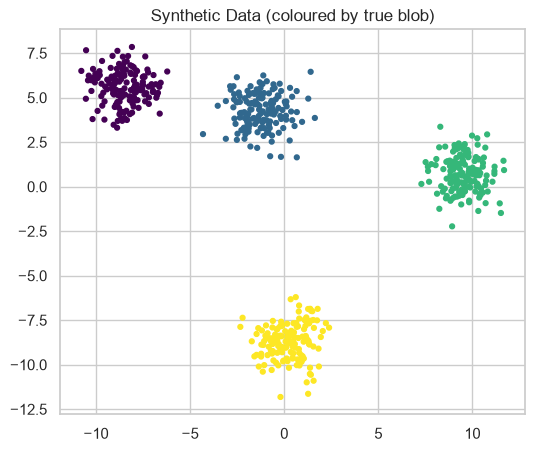

In [2]:
X, y_true = make_blobs(n_samples=600, centers=4, cluster_std=1.0,
                       random_state=7)
print('Shape:', X.shape)

plt.figure(figsize=(6, 5))
plt.scatter(X[:, 0], X[:, 1], c=y_true, cmap='viridis', s=12)
plt.title('Synthetic Data (coloured by true blob)')
plt.show()

## Implementation

In [3]:
def init_random(X, k, rng):
    """Pick k distinct data points uniformly at random."""
    return X[rng.choice(len(X), size=k, replace=False)]


def init_kmeans_pp(X, k, rng):
    """K-Means++: sample each next centroid with probability ~ D(x)^2."""
    centers = [X[rng.integers(len(X))]]
    for _ in range(1, k):
        d2 = ((X[:, None, :] - np.array(centers)[None]) ** 2).sum(axis=2)
        d2 = d2.min(axis=1)
        centers.append(X[rng.choice(len(X), p=d2 / d2.sum())])
    return np.array(centers)


def lloyd(X, k, init='k-means++', seed=0, max_iter=100):
    """Return labels, centroids, inertia per iteration, centroid history."""
    rng = np.random.default_rng(seed)
    if init == 'k-means++':
        centers = init_kmeans_pp(X, k, rng)
    else:
        centers = init_random(X, k, rng)
    history, inertia, labels = [centers], [], None

    for _ in range(max_iter):
        # assignment step
        d2 = ((X[:, None, :] - centers[None]) ** 2).sum(axis=2)
        new_labels = d2.argmin(axis=1)
        inertia.append(d2[np.arange(len(X)), new_labels].sum())
        if labels is not None and np.array_equal(new_labels, labels):
            break
        labels = new_labels
        # update step (an empty cluster keeps its old centroid)
        centers = np.array([X[labels == j].mean(axis=0)
                            if np.any(labels == j) else centers[j]
                            for j in range(k)])
        history.append(centers)
    return labels, centers, inertia, history

## Watching Lloyd's Algorithm Converge

One run from a **random** initialisation. Black crosses are the current centroids; the dashed lines are the paths they have travelled.

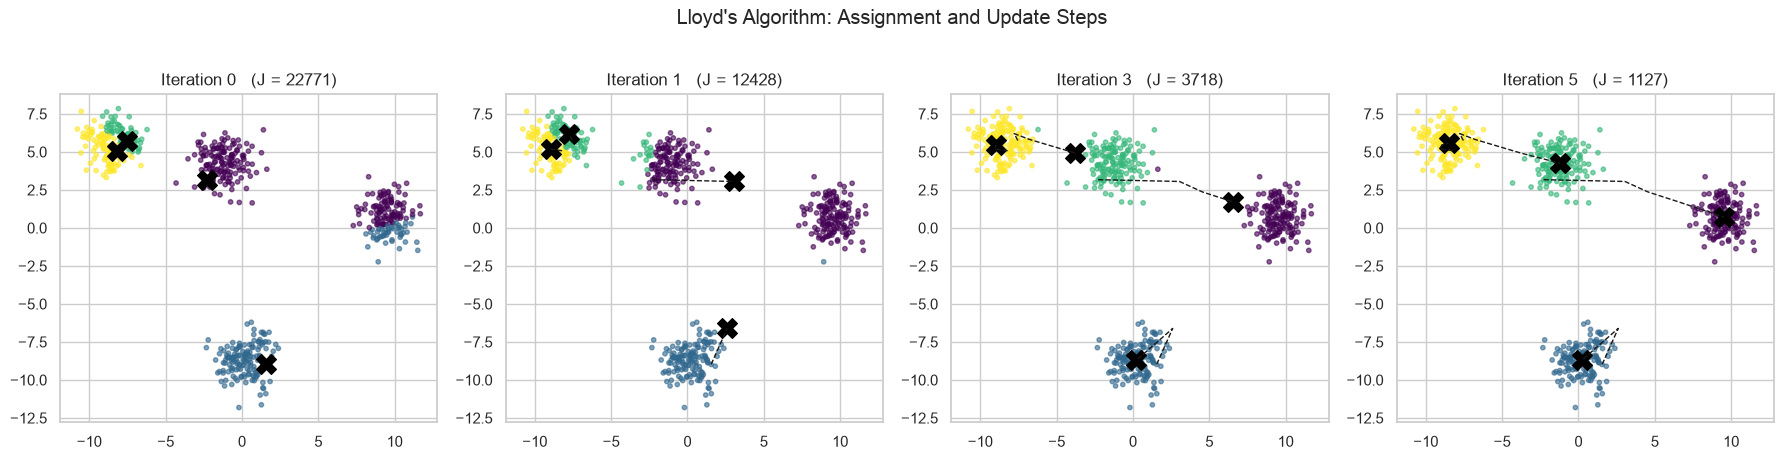

Inertia per iteration: [22771 12428  8989  3718  1128  1127]


In [4]:
labels, centers, inertia, history = lloyd(X, 4, init='random', seed=2)
steps = [0, 1, 3, len(history) - 1]

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for ax, step in zip(axes, steps):
    c = history[step]
    d2 = ((X[:, None, :] - c[None]) ** 2).sum(axis=2)
    ax.scatter(X[:, 0], X[:, 1], c=d2.argmin(axis=1), cmap='viridis',
               s=10, alpha=0.6)
    path = np.array(history[:step + 1])
    for j in range(4):
        ax.plot(path[:, j, 0], path[:, j, 1], 'k--', lw=1)
    ax.scatter(c[:, 0], c[:, 1], c='black', marker='X', s=200)
    ax.set_title(f'Iteration {step}   (J = {d2.min(axis=1).sum():.0f})')
plt.suptitle("Lloyd's Algorithm: Assignment and Update Steps", y=1.02)
plt.tight_layout()
plt.show()

print('Inertia per iteration:', np.round(inertia).astype(int))

The inertia drops at every iteration and the centroids slide towards the blob centres until the assignments stop changing.

## Random Initialisation vs K-Means++

Lloyd's algorithm is run 100 times with each initialisation (different seeds).

In [5]:
rows = []
for seed in range(100):
    for init in ['random', 'k-means++']:
        lab, _, J, _ = lloyd(X, 4, init=init, seed=seed)
        rows.append({'init': init, 'seed': seed, 'inertia': J[-1],
                     'iterations': len(J) - 1,
                     'ARI': adjusted_rand_score(y_true, lab)})
runs = pd.DataFrame(rows)

best = runs['inertia'].min()
runs['reached best'] = runs['inertia'] <= best * 1.01
runs.groupby('init')[['inertia', 'iterations', 'ARI', 'reached best']] \
    .mean().round(3)

,inertia,iterations,ARI,reached best
init,,,,
k-means++,1568.594,2.01,0.959,0.89
random,3993.492,6.37,0.819,0.51


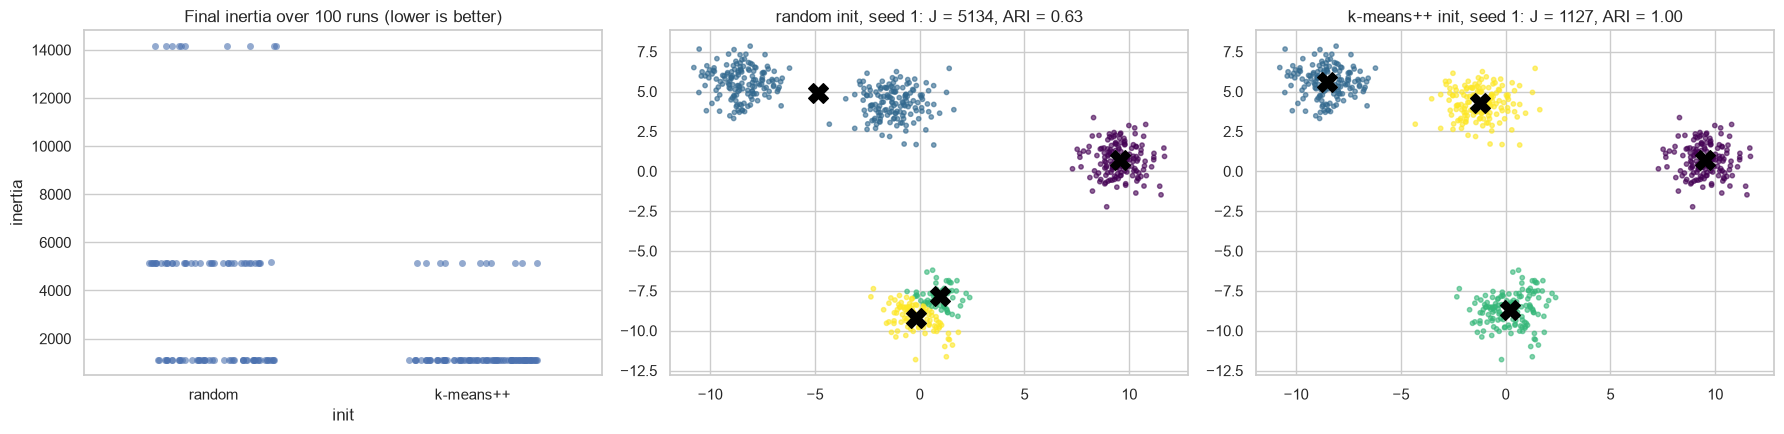

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

sns.stripplot(data=runs, x='init', y='inertia', jitter=0.25, alpha=0.6,
              ax=axes[0])
axes[0].set_title('Final inertia over 100 runs (lower is better)')

for ax, init in zip(axes[1:], ['random', 'k-means++']):
    lab, c, J, _ = lloyd(X, 4, init=init, seed=1)
    ax.scatter(X[:, 0], X[:, 1], c=lab, cmap='viridis', s=10, alpha=0.6)
    ax.scatter(c[:, 0], c[:, 1], c='black', marker='X', s=200)
    ax.set_title(f'{init} init, seed 1: J = {J[-1]:.0f}, '
                 f'ARI = {adjusted_rand_score(y_true, lab):.2f}')
plt.tight_layout()
plt.show()

With random starts, two centroids often land in the same blob and the algorithm gets stuck in a **local minimum** — two real blobs merged, one split in half. K-Means++ spreads the starting centroids out, so it reaches the best solution far more often and in fewer iterations. Running several initialisations and keeping the lowest inertia (scikit-learn's `n_init`) fixes the remaining bad runs.

## Verification against scikit-learn

In [7]:
# best of 10 K-Means++ runs, like sklearn's n_init=10
ours = min((lloyd(X, 4, seed=s) for s in range(10)), key=lambda r: r[2][-1])
sk = KMeans(n_clusters=4, init='k-means++', n_init=10, random_state=42).fit(X)

print(f'Scratch inertia : {ours[2][-1]:.2f}')
print(f'sklearn inertia : {sk.inertia_:.2f}')
print(f'Agreement between the two labelings (ARI): '
      f'{adjusted_rand_score(ours[0], sk.labels_):.3f}')

Scratch inertia : 1127.40
sklearn inertia : 1127.40
Agreement between the two labelings (ARI): 1.000


---
# Part B — Choosing K: Elbow Method & Silhouette Analysis

Both methods are tried on the blobs (where the answer is known: $K = 4$) and on the Iris flowers (3 species, but the clusters are not as clean). The four Iris features are all lengths in centimetres, so they are used unscaled.

In [8]:
iris = load_iris()
Xi = iris.data
df = pd.DataFrame(Xi, columns=iris.feature_names)
df['species'] = pd.Categorical.from_codes(iris.target, iris.target_names)
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


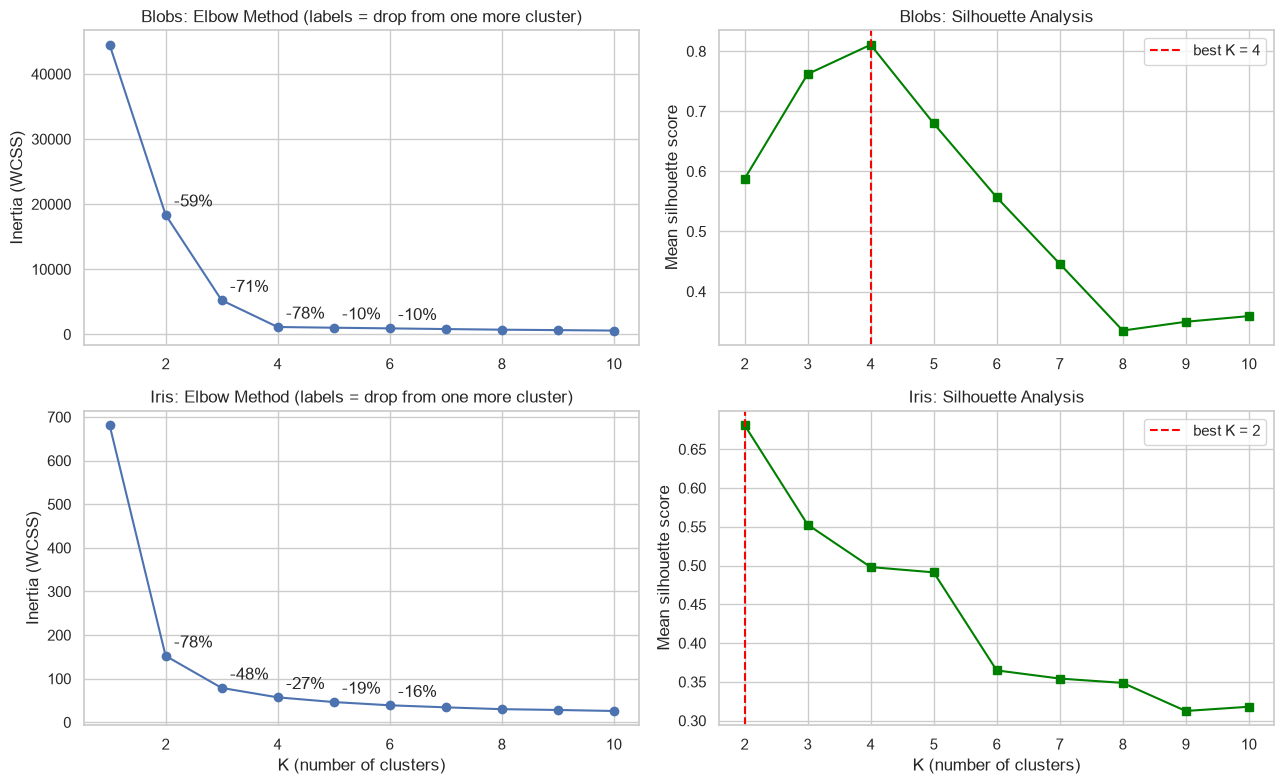

In [9]:
ks = np.arange(1, 11)
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for row, (name, data) in enumerate([('Blobs', X), ('Iris', Xi)]):
    inertias, sils = [], []
    for k in ks:
        km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(data)
        inertias.append(km.inertia_)
        if k > 1:
            sils.append(silhouette_score(data, km.labels_))
    inertias = np.array(inertias)
    drop = 1 - inertias[1:] / inertias[:-1]   # gain from adding one cluster
    k_sil = ks[1:][np.argmax(sils)]

    axes[row, 0].plot(ks, inertias, 'o-')
    for k, dk in zip(ks[1:6], drop[:5]):
        axes[row, 0].annotate(f'-{dk:.0%}', (k, inertias[k - 1]),
                              xytext=(6, 6), textcoords='offset points')
    axes[row, 0].set_ylabel('Inertia (WCSS)')
    axes[row, 0].set_title(f'{name}: Elbow Method '
                           '(labels = drop from one more cluster)')

    axes[row, 1].plot(ks[1:], sils, 's-', color='green')
    axes[row, 1].axvline(k_sil, ls='--', color='red',
                         label=f'best K = {k_sil}')
    axes[row, 1].set_ylabel('Mean silhouette score')
    axes[row, 1].set_title(f'{name}: Silhouette Analysis')
    axes[row, 1].legend()
for ax in axes[1]:
    ax.set_xlabel('K (number of clusters)')
plt.tight_layout()
plt.show()

- **Blobs:** going from 3 to 4 clusters still removes 78% of the inertia, but a 5th cluster removes only 10% — a sharp elbow at the true $K = 4$, and the silhouette peaks there too.
- **Iris:** the drops shrink gradually (78%, 48%, 27%, 19%), so the elbow is soft — somewhere around $K = 2$–3 — and the silhouette prefers $K = 2$. Versicolor and virginica overlap heavily, so geometrically Iris looks like *two* groups (setosa vs the rest). The metrics measure cluster shape, not the labels we happen to know.

## Silhouette Diagrams (Iris)

Each horizontal bar is one flower's $s(i)$, grouped by cluster and sorted. The red line is the mean silhouette.

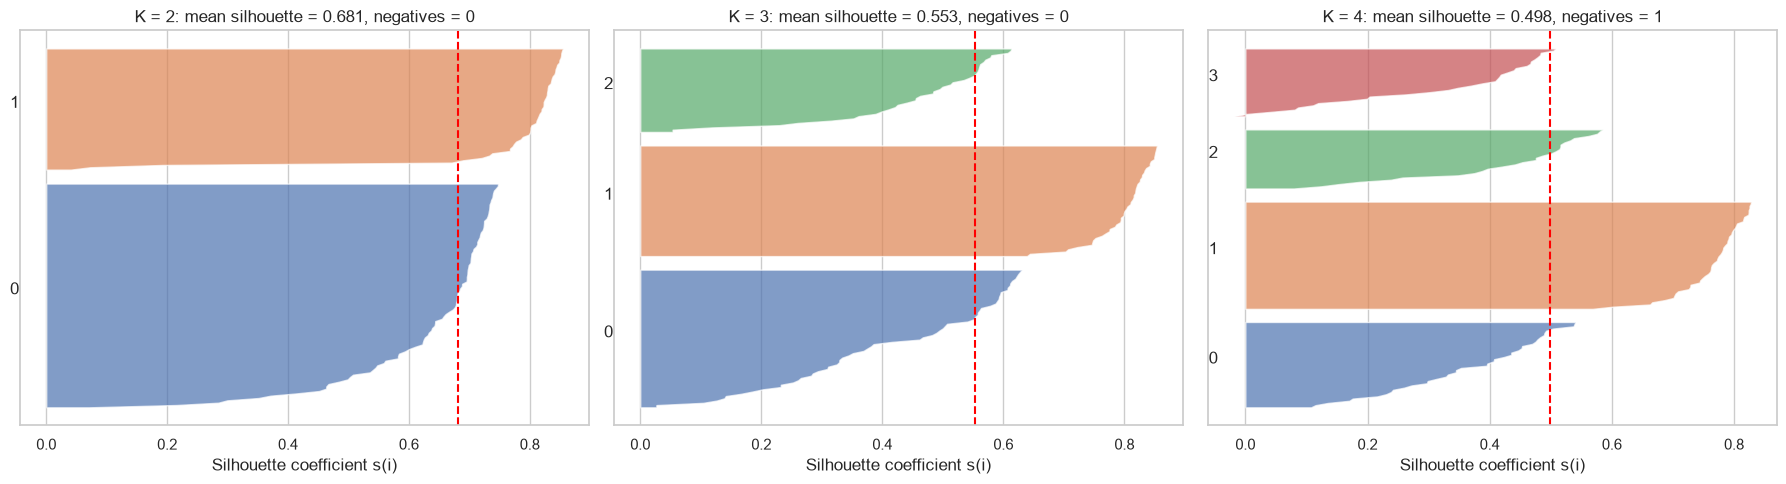

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, k in zip(axes, [2, 3, 4]):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xi)
    s = silhouette_samples(Xi, km.labels_)
    y_low = 0
    for j in range(k):
        sj = np.sort(s[km.labels_ == j])
        ax.fill_betweenx(np.arange(y_low, y_low + len(sj)), 0, sj, alpha=0.7)
        ax.text(-0.06, y_low + len(sj) / 2, str(j))
        y_low += len(sj) + 5
    ax.axvline(s.mean(), color='red', ls='--')
    ax.set_title(f'K = {k}: mean silhouette = {s.mean():.3f}, '
                 f'negatives = {(s < 0).sum()}')
    ax.set_xlabel('Silhouette coefficient s(i)')
    ax.set_yticks([])
plt.tight_layout()
plt.show()

At $K = 2$ both clusters sit well above the mean. At $K = 3$ the setosa cluster stays excellent, but the versicolor and virginica clusters have long tails of points close to 0 — flowers on the boundary between those two species. At $K = 4$ an existing cluster is split further, scores drop and the first negative silhouette appears.

## Final Model: K = 3 vs the True Species

In [11]:
km3 = KMeans(n_clusters=3, n_init=10, random_state=42).fit(Xi)
print(f'ARI vs species : {adjusted_rand_score(iris.target, km3.labels_):.3f}')
print(f'Silhouette     : {silhouette_score(Xi, km3.labels_):.3f}\n')
pd.crosstab(df['species'], km3.labels_, rownames=['Species'],
            colnames=['Cluster'])

ARI vs species : 0.730
Silhouette     : 0.553



Cluster,0,1,2
Species,,,
setosa,0,50,0
versicolor,48,0,2
virginica,14,0,36


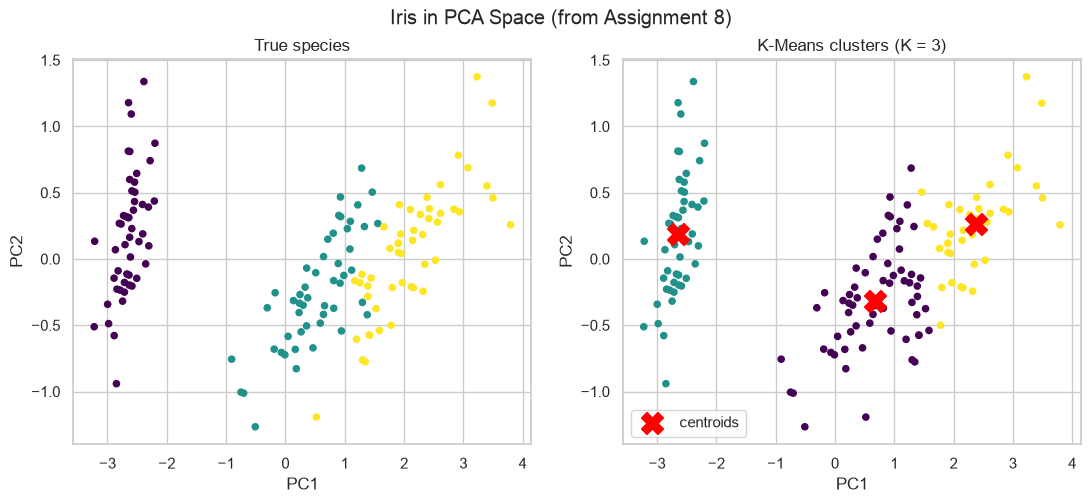

In [12]:
pca = PCA(n_components=2).fit(Xi)
P = pca.transform(Xi)
C = pca.transform(km3.cluster_centers_)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(P[:, 0], P[:, 1], c=iris.target, cmap='viridis', s=20)
axes[0].set_title('True species')
axes[1].scatter(P[:, 0], P[:, 1], c=km3.labels_, cmap='viridis', s=20)
axes[1].scatter(C[:, 0], C[:, 1], c='red', marker='X', s=250,
                label='centroids')
axes[1].set_title('K-Means clusters (K = 3)')
axes[1].legend()
for ax in axes:
    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')
plt.suptitle('Iris in PCA Space (from Assignment 8)')
plt.show()

## Conclusion

- **Lloyd's algorithm** from scratch converges in a handful of iterations and matches scikit-learn's `KMeans` exactly (same inertia, ARI = 1.0 between the two labelings).
- **Initialisation matters:** over 100 runs, random starts reached the best solution only **~51%** of the time (mean ARI $\approx$ 0.82); **K-Means++** did so **~89%** of the time (ARI $\approx$ 0.96) and needed about a third of the iterations (2.0 vs 6.4).
- **Elbow & silhouette** both recover $K = 4$ on the blobs. On Iris the elbow is soft (2–3) and the silhouette picks 2, although there are 3 species — versicolor and virginica overlap, so "best $K$" depends on the criterion and domain knowledge has to break the tie.
- **Iris with K = 3:** setosa is recovered perfectly; most errors are versicolor/virginica mix-ups (ARI $\approx$ 0.73).
- Limitations: K-Means assumes roughly spherical, similar-sized clusters, needs $K$ up front, and is sensitive to scaling and outliers. Hierarchical clustering (Assignment 10) avoids choosing $K$ in advance.